In [20]:
# Imports
import numpy as np
from datetime import datetime

import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "DejaVu Serif",
    "font.serif": ["Paletino"],
    "font.size":14,
    "mathtext.fontset" : 'dejavuserif',
    "backend":'agg'
})

from astropy.io import fits
from astropy.table import Table
from astropy.coordinates import SkyCoord  # High-level coordinates
from astropy.coordinates import angular_separation
import astropy.units as u

In [21]:
# Path to file containing positions of OHM host galaxies
ohm_file_path = 'ohm_targets.csv'

# Read file OHM host data into an astropy Table object
OHM_data = Table.read(ohm_file_path, delimiter=',', header_start=0, data_start=1)

In [22]:
ohm_coords = SkyCoord(OHM_data['RAJ2000'], OHM_data['DEJ2000'], frame='icrs', unit=(u.hourangle, u.deg))

In [23]:
# Path to file containing positions of OHM host galaxies
non_ohm_file_path = 'non_ohm_targets.csv'

# Read file OHM host data into an astropy Table object
non_OHM_data = Table.read(non_ohm_file_path, delimiter=',', header_start=0, data_start=1)
non_OHM_data[0:5]
len(non_OHM_data)

259

In [24]:
non_OHM_coords = SkyCoord(non_OHM_data['RAJ2000'], non_OHM_data['DEJ2000'], frame='icrs', unit=(u.hourangle, u.deg))

# AKARI

In [25]:
from astropy.table import Table

# Load the AKARI data using the strict CDS format reader
print("Loading AKARI FIS Catalogue...")
# Change 'fis.dat' to 'fits.dat' if you renamed the file!
akari_table = Table.read("fis.dat", format="ascii.cds", readme="ReadMe.txt")

# Verify the columns (looking for RAJ2000, DEJ2000, and the flux bands like S90)
print("--- AKARI Catalogue Columns ---")
print(akari_table.colnames)

Loading AKARI FIS Catalogue...
--- AKARI Catalogue Columns ---
['---', 'objID', 'objName', 'RAdeg', 'DEdeg', 'errMaj', 'errMin', 'errPA', 'S65', 'S90', 'S140', 'S160', 'e_S65', 'e_S90', 'e_S140', 'e_S160', 'q_S65', 'q_S90', 'q_S140', 'q_S160', '---_1', 'f_S65', '---_2', 'f_S90', '---_3', 'f_S140', '---_4', 'f_S160', 'Ns65', 'Ns90', 'Ns140', 'Ns160', 'Np65', 'Np90', 'Np140', 'Np160', 'M65', 'M90', 'M140', 'M160', 'Ndens']


In [26]:
from astropy.coordinates import SkyCoord
import astropy.units as u

# Convert the AKARI coordinates to SkyCoord objects
akari_coords = SkyCoord(ra=akari_table['RAdeg'], 
                        dec=akari_table['DEdeg'], 
                        unit=(u.deg, u.deg), 
                        frame='icrs')

In [27]:
import numpy as np

# 1. Run the Astropy KD-Tree matcher
print("Running cross-match...")
idx, d2d, d3d = ohm_coords.match_to_catalog_sky(akari_coords)

# 2. Enforce your 10-arcsecond search radius
max_sep = 10.0 * u.arcsec
sep_constraint = d2d < max_sep

# 3. Extract the successful matches
matched_ohms = ohm_coords[sep_constraint]
matched_akari_indices = idx[sep_constraint]
matched_akari_data = akari_table[matched_akari_indices]

print(f"Total OHMs Matched with AKARI: {len(matched_ohms)}")

Running cross-match...
Total OHMs Matched with AKARI: 105


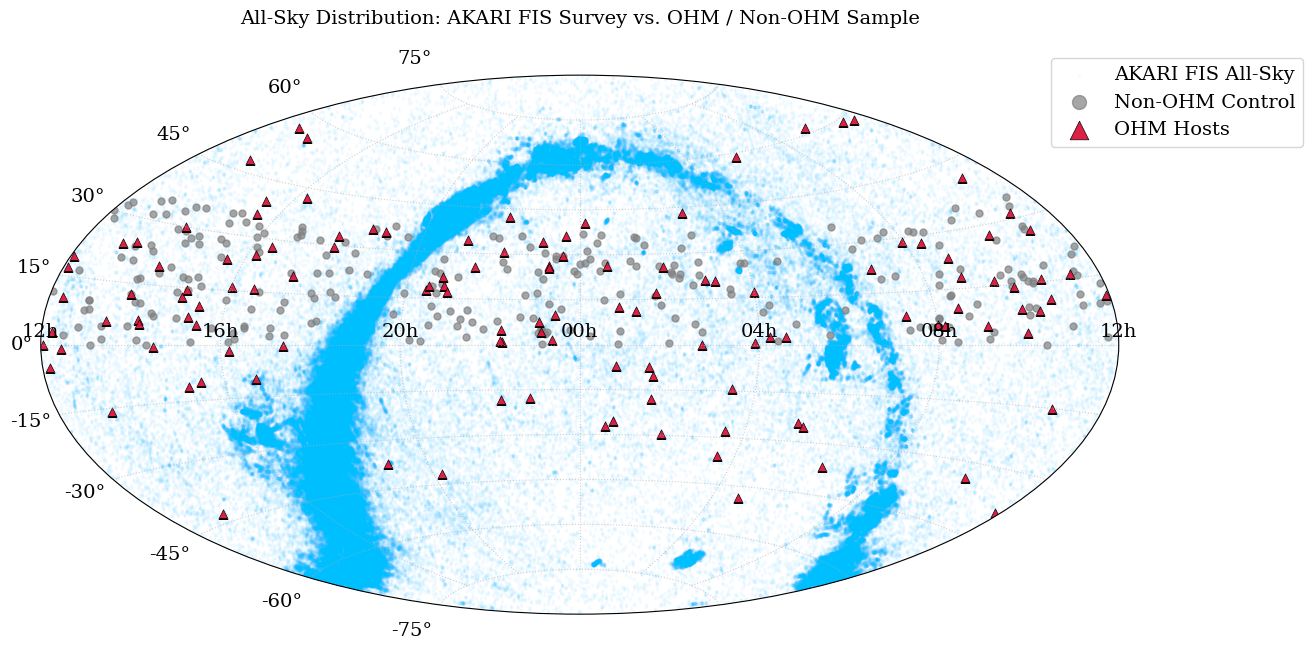

In [28]:
import matplotlib.pyplot as plt
import numpy as np
import astropy.units as u

# ---------------------------------------------------------
# 1. Convert Coordinates to Wrapped Radians (-pi to +pi)
# ---------------------------------------------------------
# AKARI All-Sky Survey
akari_ra_rad = akari_coords.ra.wrap_at(180 * u.deg).radian
akari_dec_rad = akari_coords.dec.radian

# Non-OHM Control Sample
non_ohm_ra_rad = non_OHM_coords.ra.wrap_at(180 * u.deg).radian
non_ohm_dec_rad = non_OHM_coords.dec.radian

# OHM Host Galaxies
ohm_ra_rad = OHM_coords.ra.wrap_at(180 * u.deg).radian
ohm_dec_rad = OHM_coords.dec.radian

# ---------------------------------------------------------
# 2. Build the Aitoff Projection Sky Map
# ---------------------------------------------------------
fig = plt.figure(figsize=(14, 7))
ax = fig.add_subplot(111, projection='aitoff')

# Layer 1: AKARI FIS All-Sky Survey (background)
ax.scatter(
    akari_ra_rad, 
    akari_dec_rad, 
    color='deepskyblue', 
    alpha=0.03, 
    marker=',', 
    s=1, 
    label='AKARI FIS All-Sky'
)

# Layer 2: Non-OHM Control Galaxies
ax.scatter(
    non_ohm_ra_rad, 
    non_ohm_dec_rad, 
    color='gray', 
    alpha=0.7, 
    marker='o', 
    s=25, 
    label='Non-OHM Control'
)

# Layer 3: OH Megamaser Hosts
ax.scatter(
    ohm_ra_rad, 
    ohm_dec_rad, 
    color='crimson', 
    alpha=0.95, 
    marker='^', 
    edgecolor='black', 
    linewidth=0.5,
    s=45, 
    label='OHM Hosts'
)

# ---------------------------------------------------------
# 3. Formatting, Grid, and Labels
# ---------------------------------------------------------
ax.set_title('All-Sky Distribution: AKARI FIS Survey vs. OHM / Non-OHM Sample', y=1.08, fontsize=14)
ax.grid(True, linestyle=':', alpha=0.6)

# Custom RA Tick Labels (Hours format across the oval)
ra_ticks_hours = np.array([-12, -8, -4, 0, 4, 8, 12])
ax.set_xticks(np.radians(ra_ticks_hours * 15))
ax.set_xticklabels([f'{h:02d}h' if h >= 0 else f'{h+24:02d}h' for h in ra_ticks_hours])

# Legend placed outside the main oval
ax.legend(loc='upper right', bbox_to_anchor=(1.18, 1.05), markerscale=2)

plt.savefig('AKARI_crossmatch.png', dpi=300, bbox_inches='tight')

plt.show()

In [33]:
import pandas as pd
from astropy.coordinates import SkyCoord
import astropy.units as u

# 1. Directly input the 5 Roberts et al. targets to bypass the messy text file
roberts_data = {
    'Name': ['AGC 102299', 'AGC 116345', 'AGC 193884', 'AGC 249507', 'AGC 322050'],
    'RA_str': ['00h39m24.7s', '01h16m04.0s', '09h32m38.3s', '14h03m40.3s', '22h13m06.3s'],
    'Dec_str': ['+26d04m14.4s', '+11d01m36.6s', '+16d11m57.0s', '+29d54m56.0s', '+01d16m27.0s'],
    'OH_Line_Flux_Jy_km_s': [0.67, 1.60, 2.30, 1.94, 2.89] # Added as requested by Charissa
}

roberts_df = pd.DataFrame(roberts_data)

# 2. Convert to decimal degrees for the cross-matching notebook
coords = SkyCoord(roberts_df['RA_str'], roberts_df['Dec_str'], frame='icrs')

roberts_df['RA_deg'] = coords.ra.deg
roberts_df['Dec_deg'] = coords.dec.deg

# 3. View the clean data
roberts_df[['Name', 'RA_deg', 'Dec_deg', 'OH_Line_Flux_Jy_km_s']]

,Name,RA_deg,Dec_deg,OH_Line_Flux_Jy_km_s
0,AGC 102299,9.852917,26.070667,0.67
1,AGC 116345,19.016667,11.026833,1.60
2,AGC 193884,143.159583,16.199167,2.30
3,AGC 249507,210.917917,29.915556,1.94
4,AGC 322050,333.276250,1.274167,2.89


In [34]:
glowacki_data = {
    'Name': ['LADUMA J033046.20-275518.1'],
    'RA_str': ['03h30m46.20s'],
    'Dec_str': ['-27d55m18.17s'],
    'OH_Line_Flux_Jy_km_s': [0.69],
    'Peak_Flux_mJy': [1.42],
    'z_OH': [0.5225]
}

glowacki_df = pd.DataFrame(glowacki_data)

In [35]:
import pandas as pd

jarvis_data = {
    'Name': ['J095903.22+025356.1'],
    'RA_str': ['09h59m03.22s'],
    'Dec_str': ['+02d53m56.1s'], # Assuming positive declination based on J2000 formatting
    'z_OH': [0.7092]
}

jarvis_df = pd.DataFrame(jarvis_data)

In [36]:
import pandas as pd

manamela_data = {
    'Name': ['HATLAS J142935.3-002836'],
    'RA_str': ['14h29m35.2s'],
    'Dec_str': ['-00d28m36.0s'], 
    'z_OH': [1.027]
}

manamela_df = pd.DataFrame(manamela_data)

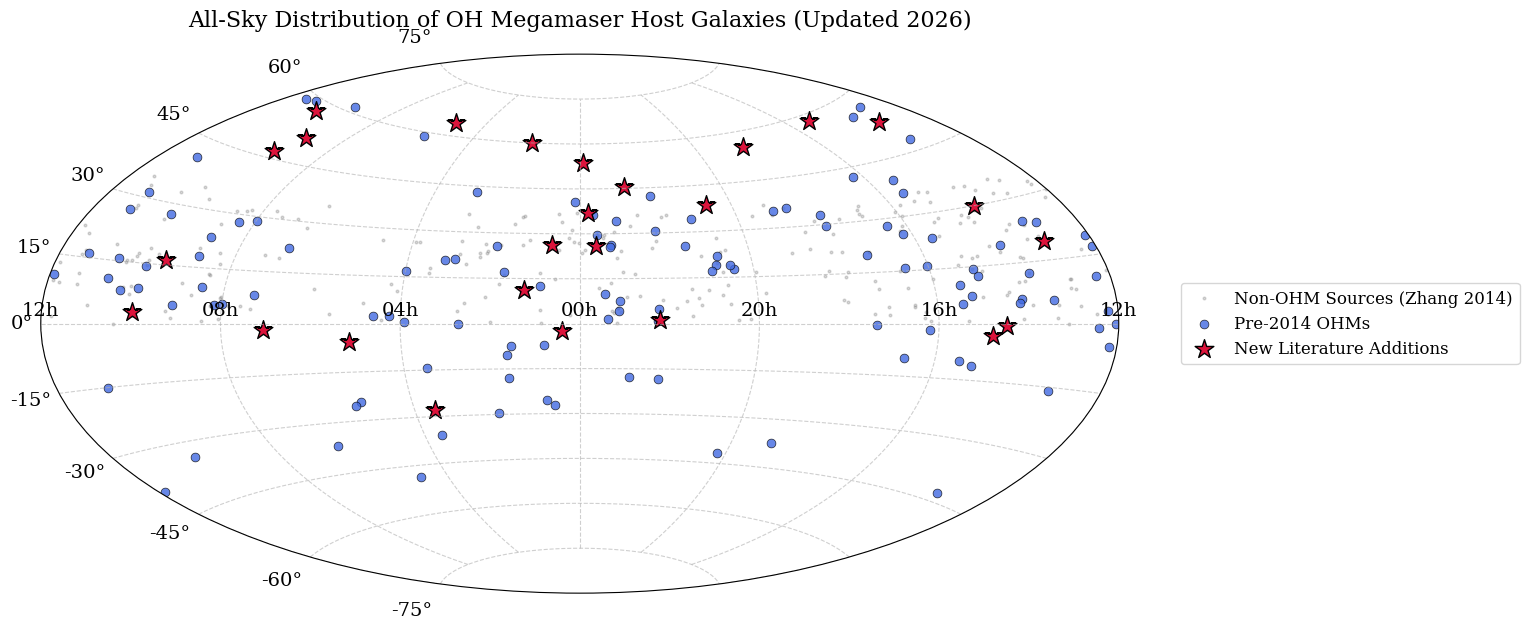

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord
import astropy.units as u

# ---------------------------------------------------------
# 1. STANDARDIZE THE ORIGINAL 2014 DATA
# ---------------------------------------------------------
ohm_df = OHM_data.to_pandas()
non_ohm_df = non_OHM_data.to_pandas()

ohm_df['is_OHM'] = True
ohm_df['is_new_literature'] = False

non_ohm_df['is_OHM'] = False
non_ohm_df['is_new_literature'] = False

# ---------------------------------------------------------
# 2. INTEGRATE NEW LITERATURE DATA (INCLUDING ZHANG 2024)
# ---------------------------------------------------------
# Load the Zhang 2024 CSV you just created
zhang_2024_df = pd.read_csv("Zhang_2024_OHM_Targets.csv")

# CRITICAL: Filter out 'Known' targets to avoid duplicating the 2014 baseline
zhang_new_df = zhang_2024_df[zhang_2024_df['Status'] == 'New'].copy()

# Rename the Zhang columns to match your pipeline's coordinate parsing
zhang_new_df.rename(columns={'RA_deg': 'RAJ2000', 'Dec_deg': 'DEJ2000'}, inplace=True)

# Combine the other scraped literature data (Roberts, Glowacki, etc.)
# Assuming roberts_df, glowacki_df, jarvis_df, manamela_df are already loaded
other_new_ohms_df = pd.concat([roberts_df, glowacki_df, jarvis_df, manamela_df], ignore_index=True)

# Translate the string coordinates for the other literature
coords_other_new = SkyCoord(other_new_ohms_df['RA_str'], other_new_ohms_df['Dec_str'], frame='icrs')
other_new_ohms_df['RAJ2000'] = coords_other_new.ra.hour
other_new_ohms_df['DEJ2000'] = coords_other_new.dec.deg

# Combine ALL new literature (Zhang + Others)
new_ohms_df = pd.concat([other_new_ohms_df, zhang_new_df], ignore_index=True)

# Add the tracking labels to the new data
new_ohms_df['is_OHM'] = True
new_ohms_df['is_new_literature'] = True

# ---------------------------------------------------------
# 3. MERGE AND CLEAN EVERYTHING
# ---------------------------------------------------------
data = pd.concat([ohm_df, non_ohm_df, new_ohms_df], ignore_index=True)
clean_data = data.dropna(subset=['RAJ2000', 'DEJ2000']).copy()

# ---------------------------------------------------------
# 4. CREATE THE MASKS
# ---------------------------------------------------------
ohm_mask = (clean_data['is_OHM'] == True) & (clean_data['is_new_literature'] == False)
non_ohm_mask = (clean_data['is_OHM'] == False)
new_lit_mask = (clean_data['is_new_literature'] == True)

# ---------------------------------------------------------
# 5. CALCULATE RADIANS FOR THE AITOFF PLOT
# ---------------------------------------------------------
# Convert to SkyCoord. Note: Since RAJ2000 contains a mix of hourangles (from old data) 
# and decimal degrees (from Zhang), we handle the conversion carefully.
coords_all = SkyCoord(ra=clean_data['RAJ2000'].values, 
                      dec=clean_data['DEJ2000'].values, 
                      unit=(u.hourangle, u.deg), # Assumes RAJ2000 is mostly hourangle
                      frame='icrs')

ra_rad = coords_all.ra.wrap_at(180 * u.deg).radian
dec_rad = coords_all.dec.radian

# ---------------------------------------------------------
# 6. GENERATE THE FINAL PLOT
# ---------------------------------------------------------
fig = plt.figure(figsize=(14, 7))
ax = fig.add_subplot(111, projection='aitoff')

# THE FIX: Multiply ra_rad by -1 to manually invert the axis mathematically
# Plot 1: Non-OHMs (Faint Background)
ax.scatter(-ra_rad[non_ohm_mask], dec_rad[non_ohm_mask], 
           color='gray', alpha=0.3, marker='.', s=15, label='Non-OHM Sources (Zhang 2014)')

# Plot 2: Pre-2014 OHMs (Blue Circles)
ax.scatter(-ra_rad[ohm_mask], dec_rad[ohm_mask], 
           color='royalblue', alpha=0.8, marker='o', s=40, edgecolors='black', linewidth=0.5, label='Pre-2014 OHMs')

# Plot 3: New Literature Additions (Bright Red Stars)
ax.scatter(-ra_rad[new_lit_mask], dec_rad[new_lit_mask], 
           color='crimson', alpha=1.0, marker='*', s=200, edgecolors='black', linewidth=1, label='New Literature Additions')

# Formatting
ax.grid(True, linestyle='--', alpha=0.6)

# Custom RA Tick Labels to reflect the inverted hours
ra_ticks_hours = np.array([12, 8, 4, 0, -4, -8, -12]) # Inverted array
ax.set_xticks(np.radians(ra_ticks_hours * 15))
ax.set_xticklabels([f'{abs(h):02d}h' if h <= 0 else f'{24-h:02d}h' for h in ra_ticks_hours])

plt.title('All-Sky Distribution of OH Megamaser Host Galaxies (Updated 2026)', pad=20, fontsize=16)
plt.legend(loc='center left', bbox_to_anchor=(1.05, 0.5), fontsize=12)

# Save and show
plt.savefig('positionsplot.png', dpi=300, bbox_inches='tight')
plt.show()

In [41]:
zhang_2024_df = pd.read_csv("Zhang_2024_OHM_Targets.csv")
zhang_new_df = zhang_2024_df[zhang_2024_df['Status'] == 'New'].copy()

zhang_new_df['RAJ2000'] = zhang_new_df['RA_deg'] / 15.0   # degrees -> hours
zhang_new_df['DEJ2000'] = zhang_new_df['Dec_deg']

In [43]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from astropy.coordinates import SkyCoord
import astropy.units as u

# ---------------------------------------------------------
# 1. Build coordinates (define these before the cross-match too)
# ---------------------------------------------------------
# AKARI FIS from VizieR (II/298) normally has RAJ2000/DEJ2000 in DEGREES.
# Check with: print(akari_table['RAJ2000'][:3], akari_table['RAJ2000'].unit)
akari_coords = SkyCoord(ra=np.asarray(akari_table['RAdeg'], dtype=float) * u.deg,
                        dec=np.asarray(akari_table['DEdeg'], dtype=float) * u.deg,
                        frame='icrs')
# OHM sample (RAJ2000 in hours, DEJ2000 in degrees)
all_coords = SkyCoord(ra=clean_data['RAJ2000'].values.astype(float) * u.hourangle,
                      dec=clean_data['DEJ2000'].values.astype(float) * u.deg,
                      frame='icrs')
ohm_coords = all_coords[ohm_mask.values]       # pre-2014 OHMs
new_coords = all_coords[new_lit_mask.values]   # new literature OHMs

# ---------------------------------------------------------
# 2. Convert to Aitoff x/y (RA flipped so it increases to the left)
# ---------------------------------------------------------
def to_xy(c):
    x = -c.ra.wrap_at(180 * u.deg).radian
    y = c.dec.radian
    return x, y

ax_x, ax_y = to_xy(akari_coords)
ohm_x, ohm_y = to_xy(ohm_coords)
new_x, new_y = to_xy(new_coords)

# ---------------------------------------------------------
# 3. AKARI density map (2D histogram)
# ---------------------------------------------------------
xedges = np.linspace(-np.pi, np.pi, 181)          # 2 deg bins
yedges = np.linspace(-np.pi/2, np.pi/2, 91)
H, _, _ = np.histogram2d(ax_x, ax_y, bins=[xedges, yedges])
H = np.ma.masked_where(H == 0, H)

# ---------------------------------------------------------
# 4. Plot
# ---------------------------------------------------------
fig = plt.figure(figsize=(14, 7))
ax = fig.add_subplot(111, projection='aitoff')

mesh = ax.pcolormesh(xedges, yedges, H.T, cmap='Greys',
                     norm=LogNorm(vmin=1, vmax=H.max()), rasterized=True)
cbar = plt.colorbar(mesh, ax=ax, orientation='horizontal', pad=0.08, shrink=0.5)
cbar.set_label('AKARI FIS sources per 2°×2° bin')

ax.scatter(ohm_x, ohm_y, color='royalblue', marker='o', s=40,
           edgecolors='black', linewidth=0.5, alpha=0.9, label='Pre-2014 OHMs', zorder=3)
ax.scatter(new_x, new_y, color='crimson', marker='*', s=200,
           edgecolors='black', linewidth=1, label='New Literature OHMs', zorder=4)

# Optional: highlight OHMs that matched AKARI within 10"
idx, d2d, _ = all_coords[(ohm_mask | new_lit_mask).values].match_to_catalog_sky(akari_coords)
matched = d2d < 10 * u.arcsec
mx, my = to_xy(all_coords[(ohm_mask | new_lit_mask).values][matched])
ax.scatter(mx, my, facecolors='none', edgecolors='gold', marker='o', s=140,
           linewidth=1.5, label=f'AKARI match <10" (N={matched.sum()})', zorder=5)

# RA tick labels: x = -RA, so RA = -x
xt_deg = np.arange(-150, 181, 30)
ax.set_xticks(np.radians(xt_deg))
ax.set_xticklabels([f'{((-d) % 360) / 15:.0f}h' for d in xt_deg])

ax.grid(True, linestyle='--', alpha=0.5)
ax.set_title('OH Megamasers over the AKARI FIS All-Sky Distribution', pad=20, fontsize=16)
ax.legend(loc='center left', bbox_to_anchor=(1.05, 0.5), fontsize=12)

plt.savefig('ohm_akari_overlay.png', dpi=300, bbox_inches='tight')
plt.show()

ValueError: could not convert string to float: '00 08 20.44'

             RA_h       Dec_d
count  412.000000  412.000000
mean    12.552377   16.630810
std      6.636303   17.486744
min      0.011417  -48.558333
25%      8.385481    5.567417
50%     13.026389   16.752667
75%     17.125486   28.118681
max     23.941861   63.944000
Loading AKARI FIS Catalogue...
AKARI sources used: 427071
AKARI sources used: 427071
Running cross-match...
Total OHMs matched with AKARI (<10"): 107 of 153


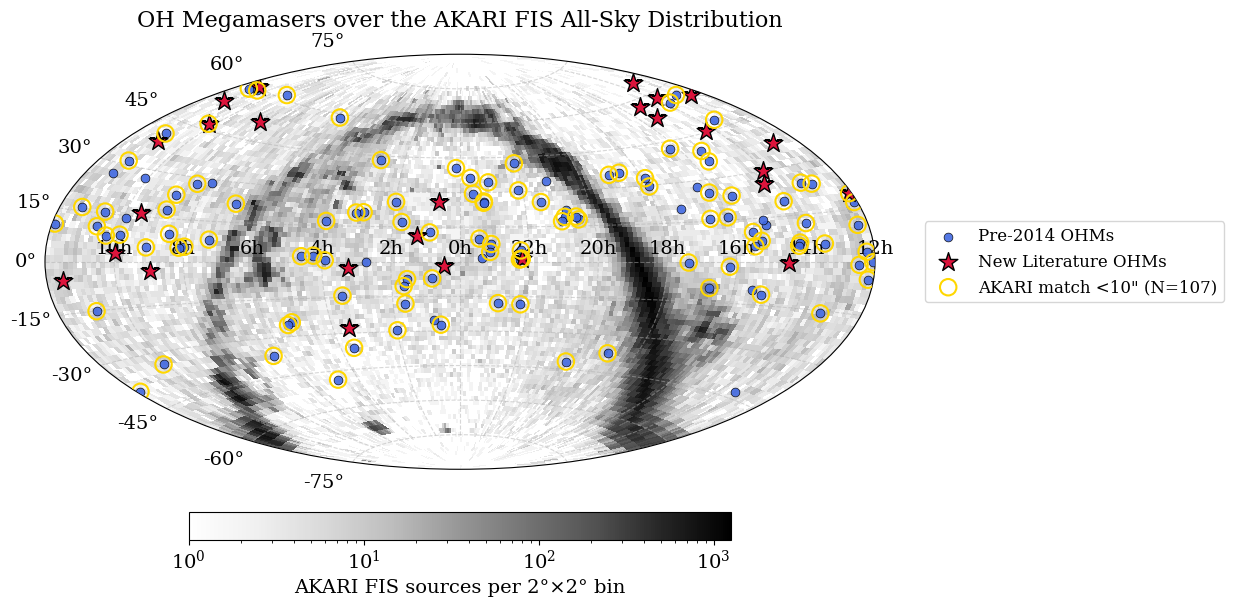

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from astropy.table import Table
from astropy.coordinates import SkyCoord, Angle
import astropy.units as u

# Assumes these already exist in your session:
#   ohm_data, non_ohm_data              (astropy Tables, 2014 data)
#   roberts_df, glowacki_df, jarvis_df, manamela_df   (with RA_str, Dec_str)
# and these files are in the working directory:
#   Zhang_2024_OHM_Targets.csv, fis.dat, ReadMe.txt

# ---------------------------------------------------------
# 1. STANDARDIZE THE ORIGINAL 2014 DATA
# ---------------------------------------------------------
ohm_df = OHM_data.to_pandas()
non_ohm_df = non_OHM_data.to_pandas()

ohm_df['is_OHM'] = True
ohm_df['is_new_literature'] = False

non_ohm_df['is_OHM'] = False
non_ohm_df['is_new_literature'] = False

# ---------------------------------------------------------
# 2. NEW LITERATURE DATA
# ---------------------------------------------------------
# Zhang 2024: re-read the CSV every run so this cell is safe to re-run
zhang_2024_df = pd.read_csv("Zhang_2024_OHM_Targets.csv")
zhang_new_df = zhang_2024_df[zhang_2024_df['Status'] == 'New'].copy()   # drop 'Known'

zhang_new_df['RAJ2000'] = zhang_new_df['RA_deg'] / 15.0    # degrees -> hours
zhang_new_df['DEJ2000'] = zhang_new_df['Dec_deg']          # degrees

# Other literature: sexagesimal strings -> hours / degrees
other_new_ohms_df = pd.concat([roberts_df, glowacki_df, jarvis_df, manamela_df],
                              ignore_index=True)
coords_other = SkyCoord(other_new_ohms_df['RA_str'], other_new_ohms_df['Dec_str'],
                        frame='icrs')
other_new_ohms_df['RAJ2000'] = coords_other.ra.hour
other_new_ohms_df['DEJ2000'] = coords_other.dec.deg

new_ohms_df = pd.concat([other_new_ohms_df, zhang_new_df], ignore_index=True)
new_ohms_df['is_OHM'] = True
new_ohms_df['is_new_literature'] = True

# ---------------------------------------------------------
# 3. MERGE AND CLEAN
# ---------------------------------------------------------
data = pd.concat([ohm_df, non_ohm_df, new_ohms_df], ignore_index=True)
clean_data = data.dropna(subset=['RAJ2000', 'DEJ2000']).reset_index(drop=True)

# ---------------------------------------------------------
# 4. PARSE MIXED COORDINATE COLUMNS (strings + floats)
# ---------------------------------------------------------
def ra_to_hours(v):
    if isinstance(v, bytes):
        v = v.decode()
    if isinstance(v, str):
        return Angle(v.strip(), unit=u.hourangle).hour   # '00 08 20.44' -> hours
    return float(v)                                       # already decimal hours

def dec_to_deg(v):
    if isinstance(v, bytes):
        v = v.decode()
    if isinstance(v, str):
        return Angle(v.strip(), unit=u.deg).deg           # '+12 34 56.7' -> degrees
    return float(v)

clean_data['RA_h'] = clean_data['RAJ2000'].apply(ra_to_hours)
clean_data['Dec_d'] = clean_data['DEJ2000'].apply(dec_to_deg)

print(clean_data[['RA_h', 'Dec_d']].describe())   # RA should be 0-24, Dec -90 to 90

# ---------------------------------------------------------
# 5. MASKS
# ---------------------------------------------------------
ohm_mask = (clean_data['is_OHM']) & (~clean_data['is_new_literature'])
non_ohm_mask = ~clean_data['is_OHM']
new_lit_mask = clean_data['is_new_literature']

# ---------------------------------------------------------
# 6. COORDINATES
# ---------------------------------------------------------
all_coords = SkyCoord(ra=clean_data['RA_h'].values * u.hourangle,
                      dec=clean_data['Dec_d'].values * u.deg,
                      frame='icrs')
ohm_coords = all_coords[ohm_mask.values]          # pre-2014 OHMs
new_coords = all_coords[new_lit_mask.values]      # new literature OHMs
non_ohm_coords = all_coords[non_ohm_mask.values]  # non-OHMs
all_ohm_coords = all_coords[(ohm_mask | new_lit_mask).values]

# ---------------------------------------------------------
# 7. LOAD AKARI FIS
# ---------------------------------------------------------
print("Loading AKARI FIS Catalogue...")
def to_float_array(col):
    """Masked/unit-carrying table column -> plain float ndarray (NaN where masked)."""
    col = col.astype(float)
    if hasattr(col, 'filled'):
        col = col.filled(np.nan)
    return np.asarray(getattr(col, 'value', col), dtype=float)

ra = to_float_array(akari_table['RAdeg'])
dec = to_float_array(akari_table['DEdeg'])
good = np.isfinite(ra) & np.isfinite(dec)

akari_coords = SkyCoord(ra=ra[good] * u.deg, dec=dec[good] * u.deg, frame='icrs')
print(f"AKARI sources used: {len(akari_coords)}")

# Optional quality cut (check meaning of q_S90 in ReadMe.txt first):
# good &= (np.asarray(akari_table['q_S90']) == 3)

akari_coords = SkyCoord(ra=ra[good] * u.deg, dec=dec[good] * u.deg, frame='icrs')
print(f"AKARI sources used: {len(akari_coords)}")

# ---------------------------------------------------------
# 8. CROSS-MATCH (10 arcsec)
# ---------------------------------------------------------
print("Running cross-match...")
idx, d2d, _ = all_ohm_coords.match_to_catalog_sky(akari_coords)
matched = d2d < 10 * u.arcsec
matched_ohms = all_ohm_coords[matched]
print(f"Total OHMs matched with AKARI (<10\"): {matched.sum()} of {len(all_ohm_coords)}")

# ---------------------------------------------------------
# 9. AITOFF XY (RA flipped so it increases to the left)
# ---------------------------------------------------------
def to_xy(c):
    return -c.ra.wrap_at(180 * u.deg).radian, c.dec.radian

ak_x, ak_y = to_xy(akari_coords)
ohm_x, ohm_y = to_xy(ohm_coords)
new_x, new_y = to_xy(new_coords)
non_x, non_y = to_xy(non_ohm_coords)
m_x, m_y = to_xy(matched_ohms)

# AKARI density map (2 deg bins)
xedges = np.linspace(-np.pi, np.pi, 181)
yedges = np.linspace(-np.pi / 2, np.pi / 2, 91)
H, _, _ = np.histogram2d(ak_x, ak_y, bins=[xedges, yedges])
H = np.ma.masked_where(H == 0, H)

# ---------------------------------------------------------
# 10. PLOT
# ---------------------------------------------------------
fig = plt.figure(figsize=(14, 7))
ax = fig.add_subplot(111, projection='aitoff')

mesh = ax.pcolormesh(xedges, yedges, H.T, cmap='Greys',
                     norm=LogNorm(vmin=1, vmax=H.max()), rasterized=True)
cbar = plt.colorbar(mesh, ax=ax, orientation='horizontal', pad=0.08, shrink=0.5)
cbar.set_label('AKARI FIS sources per 2°×2° bin')

# Uncomment to also show non-OHMs:
# ax.scatter(non_x, non_y, color='gray', alpha=0.3, marker='.', s=15,
#            label='Non-OHM Sources (Zhang 2014)', zorder=2)

ax.scatter(ohm_x, ohm_y, color='royalblue', marker='o', s=40,
           edgecolors='black', linewidth=0.5, alpha=0.9,
           label='Pre-2014 OHMs', zorder=3)
ax.scatter(new_x, new_y, color='crimson', marker='*', s=200,
           edgecolors='black', linewidth=1,
           label='New Literature OHMs', zorder=4)
ax.scatter(m_x, m_y, facecolors='none', edgecolors='gold', marker='o', s=140,
           linewidth=1.5, label=f'AKARI match <10" (N={matched.sum()})', zorder=5)

# RA tick labels: x = -RA, so RA = -x
xt_deg = np.arange(-150, 181, 30)
ax.set_xticks(np.radians(xt_deg))
ax.set_xticklabels([f'{((-d) % 360) / 15:.0f}h' for d in xt_deg])

ax.grid(True, linestyle='--', alpha=0.5)
ax.set_title('OH Megamasers over the AKARI FIS All-Sky Distribution',
             pad=20, fontsize=16)
ax.legend(loc='center left', bbox_to_anchor=(1.05, 0.5), fontsize=12)

plt.savefig('ohm_akari_overlay.png', dpi=300, bbox_inches='tight')
plt.show()